# 01 — Revenue metrics: MRR, NRR / GRR and why expansion slowed in Q3 2026

**Revenue Analytics · data as of 30 Sep 2026 · synthetic data** (see `docs/data_model.md`)
Request: *"The board wants NRR. Expansion clearly slowed last quarter — why?"* (`docs/01_request_and_scope.md`, questions Q1–Q2)

In [1]:
import pandas as pd
from saas_rev import marts, theme
from saas_rev.nbutil import md, setup, show
from saas_rev.analysis import metrics as M
from saas_rev.theme import money, pct, pts, qname
setup()
k = M.key_numbers()
q = M.quarterly_base()
# the April packaging change date is owned by 02_plan_transitions; used here only to place the timing of a decline
tr = marts.read_key_numbers("transitions")
pkg = tr.get("packaging_change_date")
pkg = pd.Timestamp(pkg) if pkg else None
plan_q = k["plan_upgrade_fall_main_quarter"]
plan_before_pkg = bool(pkg is not None and pd.Period(plan_q.replace("-", ""), freq="Q").end_time < pkg)
pkg_clause = f", before the {pkg:%B} packaging change" if plan_before_pkg else ""
ratio = k["contraction_rate_q3_2026"] / k["contraction_rate_q3_2025"]
contraction_word = "more than doubled" if ratio >= 2 else "nearly doubled" if ratio >= 1.8 else f"rose {pct(ratio - 1, 0)}"

## TL;DR

In [2]:
md(f"""
- **ARR {money(k['arr'])}** at 30 Sep 2026 ({k['paying_customers']:,} paying customers), up {pct(k['mrr_yoy_growth'], 0)} year over year — growth is still mostly new logos
  ({pct(q.loc['2026-Q3', 'new_rate'])} of starting MRR in Q3 vs {pct(k['expansion_rate_q3_2026'])} from expansion).
- **12-month NRR {pct(k['nrr_ttm'])}, GRR {pct(k['grr_ttm'])}.** NRR is {pts(k['nrr_ttm_2026_06'] - k['nrr_ttm']).lstrip('+')} below June ({pct(k['nrr_ttm_2026_06'])})
  and {pts(k['nrr_ttm_2025_09'] - k['nrr_ttm']).lstrip('+')} below Sep 2025. Both figures include the {k['one_off_company']} rollout: without it NRR is {pct(k['nrr_ttm_ex_one_off'])},
  down from {pct(k['nrr_ttm_2026_06_ex_one_off'])} in June, so the fall is not the one-off unwinding.
  The Q3 run-rate (one quarter, annualised) is {pct(k['nrr_runrate_q3_2026'])} vs {pct(k['nrr_runrate_q3_2025'])} a year ago, so the 12-month figure will keep falling if Q3 repeats.
- **Expansion fell {pct(-k['expansion_change_qoq'], 0)} QoQ** ({money(k['expansion_q2_2026'])} → {money(k['expansion_q3_2026'])}). {pct(k['one_off_share_of_q2'], 0)} of Q2's expansion was the one-off rollout.
  Like for like the expansion rate fell from {pct(k['expansion_rate_q2_2026_ex_one_off'])} to {pct(k['expansion_rate_q3_2026'])} of starting MRR, and from {pct(k['expansion_rate_q3_2025'])} a year earlier.
- **Structural drivers (year-over-year bridge):** Technology accounts ({money(k['bridge_yoy']['Technology (all)'])}) all but stopped expanding — expansion
  {pct(k['tech_base_expansion_rate_q3_2025'])} → {pct(k['tech_base_expansion_rate_q3_2026'])} of their own MRR a quarter — and started cutting (contraction {pct(k['tech_base_contraction_rate_q3_2025'])} → {pct(k['tech_base_contraction_rate_q3_2026'])}).
  Non-Tech plan upgrades ({money(k['bridge_yoy']['Non-Tech plan upgrades'])}): outside Paid Social the monthly Basic upgrade rate fell in two steps,
  {pct(tr['non_ps_rate_apr_sep_2025'], 1)} (Apr–Sep 2025) → {pct(tr['non_ps_rate_oct_2025_mar_2026'], 1)} (Oct 2025 – Mar 2026), before anything changed, → {pct(tr['upgrade_rate_non_ps_post'], 1)} after the April packaging change (`02_plan_transitions`).
  Non-Tech seat expansion improved ({money(k['bridge_yoy']['Non-Tech seat expansion'])}).
- **Contraction {contraction_word}** ({pct(k['contraction_rate_q3_2025'])} → {pct(k['contraction_rate_q3_2026'])} of starting MRR per quarter) — see `04_silent_churn`.
""")


- **ARR $24.8M** at 30 Sep 2026 (4,117 paying customers), up 76% year over year — growth is still mostly new logos
  (11.8% of starting MRR in Q3 vs 3.4% from expansion).
- **12-month NRR 103.5%, GRR 84.6%.** NRR is 3.5 pts below June (107.0%)
  and 1.3 pts below Sep 2025. Both figures include the Lakewave Payments rollout: without it NRR is 101.0%,
  down from 104.1% in June, so the fall is not the one-off unwinding.
  The Q3 run-rate (one quarter, annualised) is 92.9% vs 103.6% a year ago, so the 12-month figure will keep falling if Q3 repeats.
- **Expansion fell 33% QoQ** ($94.9K → $63.7K). 28% of Q2's expansion was the one-off rollout.
  Like for like the expansion rate fell from 4.2% to 3.4% of starting MRR, and from 4.9% a year earlier.
- **Structural drivers (year-over-year bridge):** Technology accounts (−$22.3K) all but stopped expanding — expansion
  6.2% → 1.2% of their own MRR a quarter — and started cutting (contraction 0.9% → 5.7%).
  Non-Tech plan upgrades (−$15.6K): outside Paid Social the monthly Basic upgrade rate fell in two steps,
  1.9% (Apr–Sep 2025) → 1.4% (Oct 2025 – Mar 2026), before anything changed, → 0.8% after the April packaging change (`02_plan_transitions`).
  Non-Tech seat expansion improved ($9.4K).
- **Contraction nearly doubled** (1.4% → 2.6% of starting MRR per quarter) — see `04_silent_churn`.


## Question
1. What are NRR and GRR, defined the way the board pack will footnote them, and how have they trended?
2. How much did expansion slow in Q3 2026, and how much of the change is a one-off, seasonality, specific segments, fewer plan upgrades vs fewer seat additions?

**Decision it feeds:** the VP's trigger (scope doc §3) — if the Q3 expansion rate excluding the rollout is within 0.5 pt of Q3 2025, call it timing; if it is ≥ 1.0 pt below, re-forecast and name the structural drivers.

## Data
| Table (SQL file) | Grain | Used for |
|---|---|---|
| `fct_customer_mrr_monthly` (`sql/20`) | customer × month-end | MRR, NRR / GRR, cohorts |
| `fct_mrr_movements` (`sql/21`) | customer × month | new / expansion / contraction / churn / reactivation |
| `fct_mrr_movement_components` (`sql/22`) | continuing customer × month | what drove each change (plan, seats, billing, discount) |
| `rpt_mrr_waterfall_monthly`, `rpt_mrr_quarterly` (`sql/23`, `24`) | month / quarter | waterfall and movement rates |
| `rpt_nrr_grr_ttm`, `rpt_nrr_quarterly_runrate` (`sql/25`) | month-end / quarter-end | headline retention |
| `rpt_segment_retention_ttm` (`sql/26`), `rpt_cohort_retention` (`sql/27`) | month × group / cohort × age | segment and cohort views |

Internal / test accounts are excluded; all definitions are in `docs/02_metric_definitions.md`. MRR, movements, NRR and GRR were re-implemented independently in Python and match the SQL to the cent (`docs/03_data_quality_checks.md`).

## Method
- **MRR** = month-end snapshot of each live subscription's price (annual ÷ 12, net of recurring discounts).
- **Movements** compare each customer's MRR with the previous month-end; the monthly identity start + movements = end holds to the cent.
- **NRR / GRR (TTM)**: same customers as 12 months earlier, point-to-point; GRR caps each customer at its starting MRR.
- **Expansion bridge.** Every expanding customer-month goes to exactly one driver bucket — Technology accounts, or non-Tech by the dominant component (seats / plan / other) — so buckets add up. Steps: (1) remove the one-off rollout (a single account worth > 10% of the quarter's expansion, confirmed by Sales); (2) base growth = the earlier quarter's like-for-like rate × (this quarter's starting MRR − the earlier quarter's starting MRR); (3) each bucket's rate change × this quarter's starting MRR. Two bridges: vs Q2 2026 (the VP's framing) and vs Q3 2025 (same season — the primary view for structural drivers).

## Results
### 1. MRR and the monthly waterfall

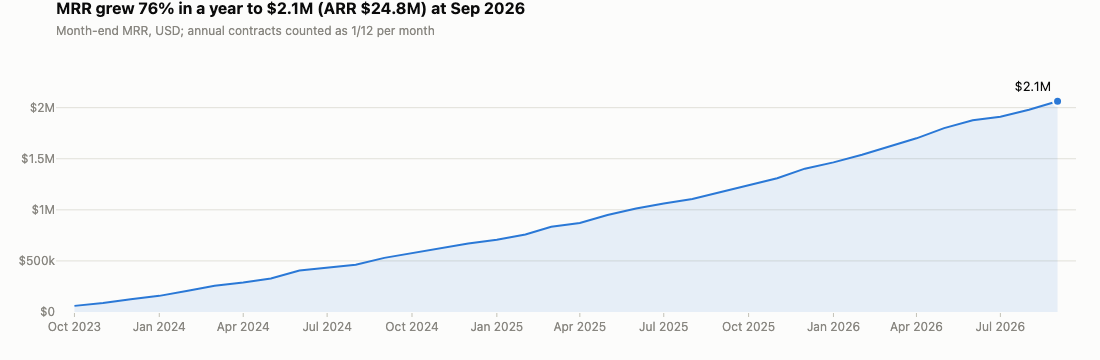

In [3]:
show(M.fig_mrr_trend())

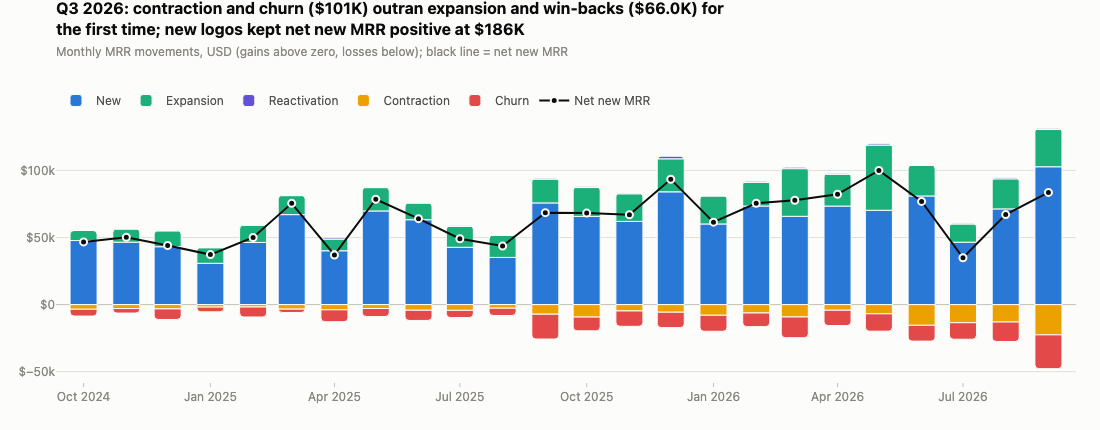

In [4]:
show(M.fig_monthly_movements())

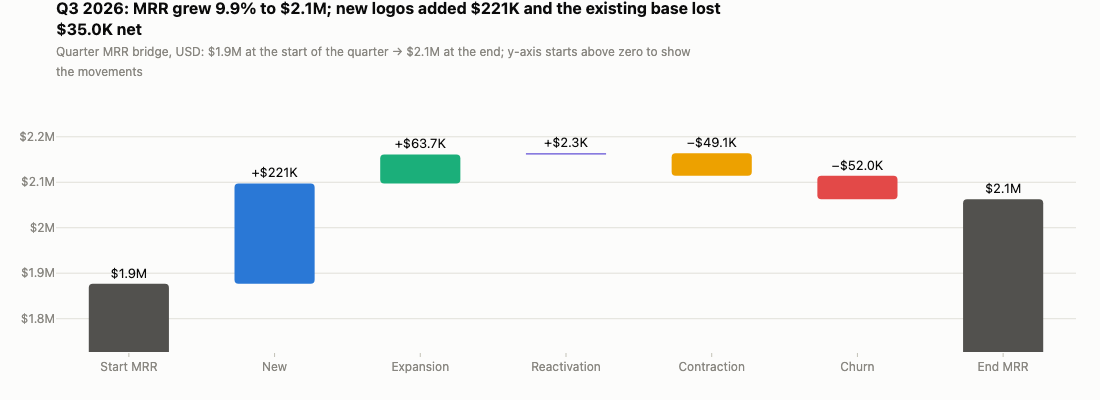

In [5]:
show(M.fig_quarter_waterfall('2026-Q3'))

In [6]:
q = M.quarterly_base()
cols = ['mrr_start_of_quarter', 'new_mrr', 'expansion_mrr', 'reactivation_mrr', 'contraction_mrr', 'churn_mrr',
        'mrr_end_of_quarter', 'expansion_rate', 'contraction_rate', 'churn_rate']
q.loc['2024-Q4':, cols]

,mrr_start_of_quarter,new_mrr,expansion_mrr,reactivation_mrr,contraction_mrr,churn_mrr,mrr_end_of_quarter,expansion_rate,contraction_rate,churn_rate
quarter_label,,,,,,,,,,
2024-Q4,"529,745.4800","137,435.2600","29,149.5200",306.0000,"9,658.2000","16,290.5000","670,687.5600",0.0550,0.0182,0.0308
2025-Q1,"670,687.5600","144,200.0000","38,609.7800",480.0000,"7,076.8800","13,406.9200","833,493.5400",0.0576,0.0106,0.0200
2025-Q2,"833,493.5400","173,204.6000","38,434.6000","1,425.0000","11,006.4100","22,466.0000","1,013,085.3300",0.0461,0.0132,0.0270
2025-Q3,"1,013,085.3300","153,701.1800","49,591.7800","1,480.0000","14,117.3100","29,358.1200","1,174,382.8600",0.0490,0.0139,0.0290
2025-Q4,"1,174,382.8600","211,832.5800","66,663.6200","2,991.0000","19,723.0200","33,187.6400","1,402,959.4000",0.0568,0.0168,0.0283
2026-Q1,"1,402,959.4000","199,391.0800","73,997.2800","2,378.0000","23,454.8000","37,533.2000","1,617,737.7600",0.0527,0.0167,0.0268
2026-Q2,"1,617,737.7600","224,757.4000","94,897.8000","2,166.0000","26,525.0000","36,133.9200","1,876,900.0400",0.0587,0.0164,0.0223
2026-Q3,"1,876,900.0400","220,625.4600","63,726.9600","2,322.0000","49,061.8400","51,967.4800","2,062,545.1400",0.0340,0.0261,0.0277


In [7]:
gains = q['expansion_mrr'] + q['reactivation_mrr']
losses = q['contraction_mrr'] + q['churn_mrr']
earlier = q.index < '2026-Q3'
first = bool(losses['2026-Q3'] > gains['2026-Q3'] and (losses[earlier] <= gains[earlier]).all())
md(f"""**Reading.** New logos still add about {pct(q.loc['2026-Q3','new_rate'])} of starting MRR a quarter. The change in Q3 is in the existing base:
expansion {pct(q.loc['2025-Q3','expansion_rate'])} → {pct(q.loc['2026-Q3','expansion_rate'])}, contraction {pct(q.loc['2025-Q3','contraction_rate'])} → {pct(q.loc['2026-Q3','contraction_rate'])},
churn {pct(q.loc['2025-Q3','churn_rate'])} → {pct(q.loc['2026-Q3','churn_rate'])} of starting MRR (Q3 2025 → Q3 2026).
In Q3 2026 contraction and churn ({money(losses['2026-Q3'])}) {'exceeded' if losses['2026-Q3'] > gains['2026-Q3'] else 'stayed below'} expansion and win-backs ({money(gains['2026-Q3'])}){' for the first time in the series' if first else ''}.""")

**Reading.** New logos still add about 11.8% of starting MRR a quarter. The change in Q3 is in the existing base:
expansion 4.9% → 3.4%, contraction 1.4% → 2.6%,
churn 2.9% → 2.8% of starting MRR (Q3 2025 → Q3 2026).
In Q3 2026 contraction and churn ($101K) exceeded expansion and win-backs ($66.0K) for the first time in the series.

### 2. NRR and GRR

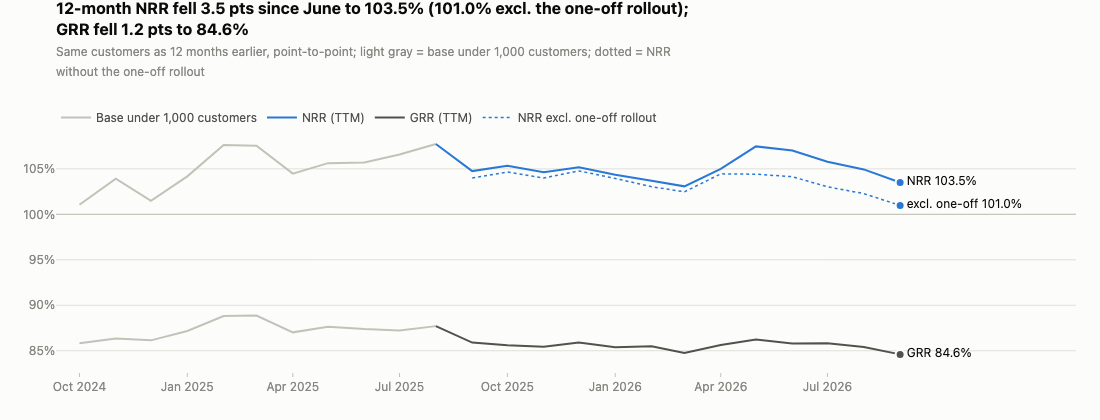

In [8]:
show(M.fig_nrr_trend())

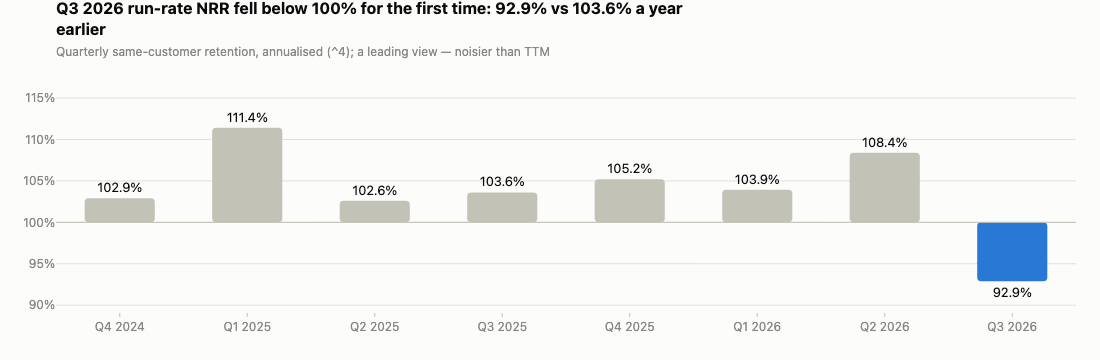

In [9]:
show(M.fig_nrr_runrate())

In [10]:
n = marts.load('rpt_nrr_grr_ttm').set_index('month_end')
n.loc['2025-09-30':, ['base_customers', 'nrr', 'grr', 'logo_retention', 'expansion_contribution', 'contraction_contribution', 'churn_contribution']]

,base_customers,nrr,grr,logo_retention,expansion_contribution,contraction_contribution,churn_contribution
month_end,,,,,,,
2025-09-30,1118,1.0475,0.8590,0.8113,0.1886,-0.0436,-0.0974
2025-10-31,1215,1.0534,0.8560,0.8123,0.1974,-0.0500,-0.0940
2025-11-30,1318,1.0463,0.8544,0.8126,0.1919,-0.0494,-0.0962
2025-12-31,1405,1.0519,0.8591,0.8192,0.1928,-0.0476,-0.0933
2026-01-31,1493,1.0436,0.8538,0.8185,0.1898,-0.0485,-0.0977
2026-02-28,1591,1.0369,0.8549,0.8108,0.1820,-0.0482,-0.0968
2026-03-31,1738,1.0308,0.8476,0.8090,0.1832,-0.0503,-0.1021
2026-04-30,1822,1.0499,0.8564,0.8172,0.1935,-0.0504,-0.0932
2026-05-31,1931,1.0747,0.8624,0.8172,0.2123,-0.0489,-0.0886


In [11]:
nx = marts.load('metrics__nrr_ex_one_off').set_index('month_end')['nrr_ex']
rep = n[n['is_reportable']]
peak = rep['nrr'].idxmax()
falling = bool((rep.loc[peak:, 'nrr'].diff().dropna() < 0).all())
at_peak = f"{peak:%Y-%m}" == k['one_off_month']
ex_low = bool(nx.loc[rep.index].idxmin() == rep.index.max())
md(f"""**Reading.** At 30 Sep 2026 the {k['nrr_base_customers']:,} customers who were paying a year earlier pay {pct(k['nrr_ttm'])} of what they paid then
(GRR {pct(k['grr_ttm'])}). Points before {rep.index.min():%b %Y} rest on fewer than 1,000 customers and are drawn in light gray.
NRR peaked at {pct(rep.loc[peak, 'nrr'])} in {peak:%B %Y}{', the month of the one-off rollout,' if at_peak else ''} and has {'fallen every month since' if falling else 'moved since'};
without the rollout it went from {pct(k['nrr_ttm_2026_06_ex_one_off'])} (June) to {pct(k['nrr_ttm_ex_one_off'])} (September){', the lowest since the base passed 1,000 customers' if ex_low else ''}.""")

**Reading.** At 30 Sep 2026 the 2,377 customers who were paying a year earlier pay 103.5% of what they paid then
(GRR 84.6%). Points before Sep 2025 rest on fewer than 1,000 customers and are drawn in light gray.
NRR peaked at 107.5% in May 2026, the month of the one-off rollout, and has fallen every month since;
without the rollout it went from 104.1% (June) to 101.0% (September), the lowest since the base passed 1,000 customers.

### 3. Why expansion slowed — two bridges

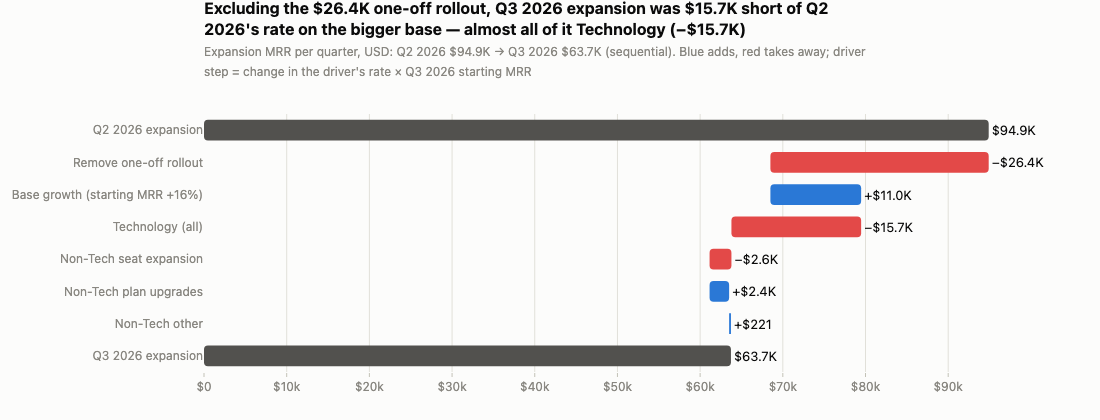

In [12]:
show(M.fig_bridge('qoq'))

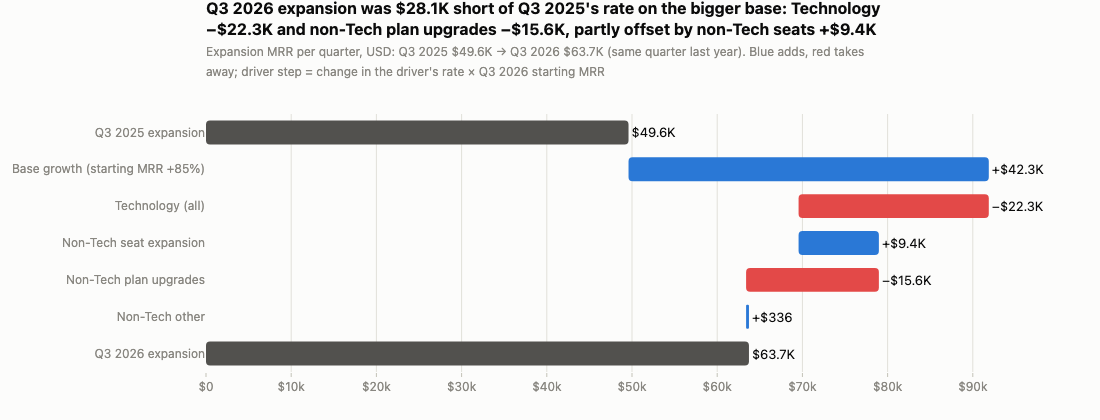

In [13]:
show(M.fig_bridge('yoy'))

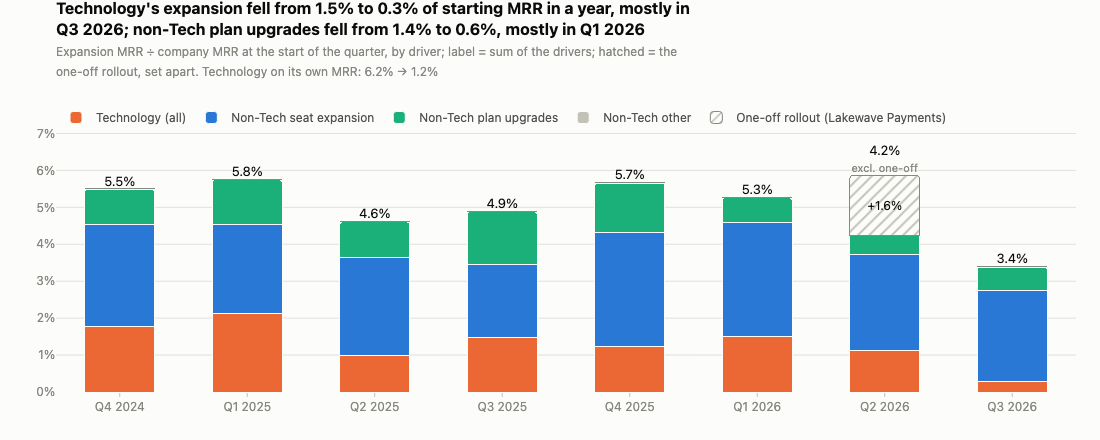

In [14]:
show(M.fig_expansion_rate_by_bucket())

In [15]:
b = marts.load('metrics__bridges')
b[['bridge', 'step', 'value', 'rate_from', 'rate_to']]

,bridge,step,value,rate_from,rate_to
0,2026-Q2 -> 2026-Q3,Q2 2026 expansion,"94,897.8000",NaN,NaN
1,2026-Q2 -> 2026-Q3,Remove one-off rollout,"-26,400.0000",NaN,NaN
2,2026-Q2 -> 2026-Q3,Base growth (starting MRR +16%),"10,973.3768",NaN,NaN
3,2026-Q2 -> 2026-Q3,Technology (all),"-15,685.7671",0.0112,0.0028
4,2026-Q2 -> 2026-Q3,Non-Tech seat expansion,"-2,643.1900",0.0261,0.0247
5,2026-Q2 -> 2026-Q3,Non-Tech plan upgrades,"2,364.1832",0.0049,0.0062
6,2026-Q2 -> 2026-Q3,Non-Tech other,220.5570,0.0001,0.0002
7,2026-Q2 -> 2026-Q3,Q3 2026 expansion,"63,726.9600",NaN,NaN
8,2025-Q3 -> 2026-Q3,Q3 2025 expansion,"49,591.7800",NaN,NaN
9,2025-Q3 -> 2026-Q3,Base growth (starting MRR +85%),"42,284.7985",NaN,NaN


In [16]:
s = M.seasonality_q2_q3()
qoq, yoy = k['bridge_qoq'], k['bridge_yoy']
non_tech_qoq = sum(v for name, v in qoq.items() if name.startswith('Non-Tech'))
below = k['expansion_rate_q3_2025'] - k['expansion_rate_q3_2026']
verdict = ('**structural** (at least 1.0 pt below Q3 2025)' if below >= 0.01 else
           '**timing** (within 0.5 pt of Q3 2025)' if below <= 0.005 else 'between the two lines (0.5–1.0 pt below Q3 2025)')
piv = M.bucket_rate_table(separate_one_offs=True, start='2025-Q3')
tech_q = k['tech_expansion_fall_main_quarter']
md(f"""**Reading.**
- *Sequential:* the {money(k['one_off_expansion_mrr'])} rollout at {k['one_off_company']} explains most of the dollar drop. After removing it and allowing for a
  bigger base, Technology accounts take away {money(-qoq['Technology (all)'])}; the three non-Tech drivers net to {money(non_tech_qoq)}.
- *Year over year (same season):* the expansion rate fell {pts(below).lstrip('+')}. Technology accounts
  ({money(yoy['Technology (all)'])}) and non-Tech plan upgrades ({money(yoy['Non-Tech plan upgrades'])}) explain the shortfall against a bigger base; non-Tech seat
  expansion was *higher* ({money(yoy['Non-Tech seat expansion'])}). Under the VP's trigger this is {verdict}.
- *When each driver fell (driver chart, share of company starting MRR):* Technology {pct(piv.loc['2025-Q3', 'Technology (all)'])} → {pct(piv.loc['2026-Q3', 'Technology (all)'])},
  {pct(k['tech_expansion_fall_main_share'], 0)} of the fall in {qname(tech_q)}. On Technology's own MRR, expansion went from {pct(k['tech_base_expansion_rate_q3_2025'])} to
  {pct(k['tech_base_expansion_rate_q3_2026'])} and contraction from {pct(k['tech_base_contraction_rate_q3_2025'])} to {pct(k['tech_base_contraction_rate_q3_2026'])} (Q3 2025 → Q3 2026).
  Non-Tech plan upgrades {pct(piv.loc['2025-Q3', 'Non-Tech plan upgrades'])} → {pct(piv.loc['2026-Q3', 'Non-Tech plan upgrades'])}; on this dollar measure the largest quarterly step
  ({pct(k['plan_upgrade_fall_main_share'], 0)} of the fall) came in {qname(plan_q)}{pkg_clause}, but the bucket is a few dozen upgrades a quarter and its timing is lumpy.
  Per Basic account (outside Paid Social) the upgrade rate fell in two steps of similar size, the second after April — see `02_plan_transitions`.
- *Seasonality:* Q2 → Q3 moved {pts(s.loc[0,'change_pts'])} in 2024 and {pts(s.loc[1,'change_pts'])} in 2025. Two observations cannot separate a summer
  effect from noise; the year-over-year bridge avoids the question.
- The plan-upgrade slowdown is analysed in `02_plan_transitions` (packaging change vs Paid Social mix vs the earlier drift); the Technology contraction in `04_silent_churn`.""")

**Reading.**
- *Sequential:* the $26.4K rollout at Lakewave Payments explains most of the dollar drop. After removing it and allowing for a
  bigger base, Technology accounts take away $15.7K; the three non-Tech drivers net to −$58.
- *Year over year (same season):* the expansion rate fell 1.5 pts. Technology accounts
  (−$22.3K) and non-Tech plan upgrades (−$15.6K) explain the shortfall against a bigger base; non-Tech seat
  expansion was *higher* ($9.4K). Under the VP's trigger this is **structural** (at least 1.0 pt below Q3 2025).
- *When each driver fell (driver chart, share of company starting MRR):* Technology 1.5% → 0.3%,
  70% of the fall in Q3 2026. On Technology's own MRR, expansion went from 6.2% to
  1.2% and contraction from 0.9% to 5.7% (Q3 2025 → Q3 2026).
  Non-Tech plan upgrades 1.4% → 0.6%; on this dollar measure the largest quarterly step
  (77% of the fall) came in Q1 2026, before the April packaging change, but the bucket is a few dozen upgrades a quarter and its timing is lumpy.
  Per Basic account (outside Paid Social) the upgrade rate fell in two steps of similar size, the second after April — see `02_plan_transitions`.
- *Seasonality:* Q2 → Q3 moved −0.9 pts in 2024 and +0.3 pts in 2025. Two observations cannot separate a summer
  effect from noise; the year-over-year bridge avoids the question.
- The plan-upgrade slowdown is analysed in `02_plan_transitions` (packaging change vs Paid Social mix vs the earlier drift); the Technology contraction in `04_silent_churn`.

### 4. Which customer groups retain best

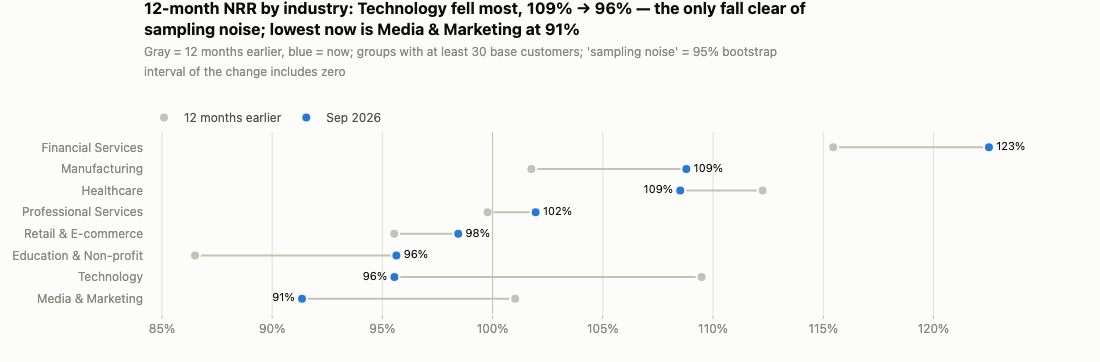

In [17]:
show(M.fig_segment_dumbbell('industry'))

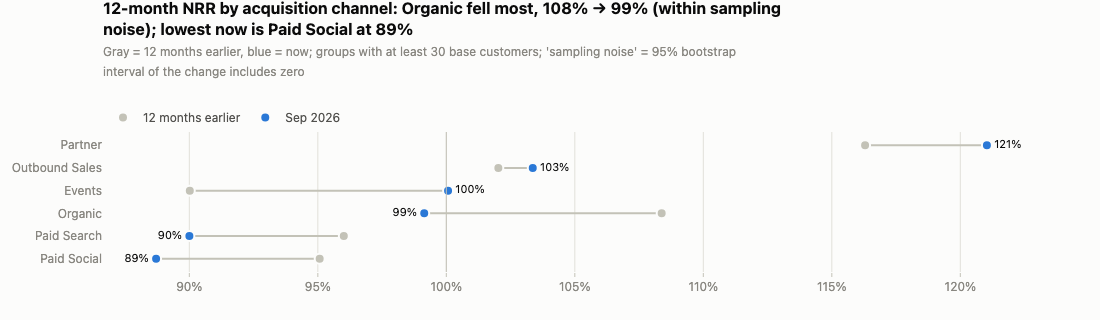

In [18]:
show(M.fig_segment_dumbbell('acquisition_channel'))

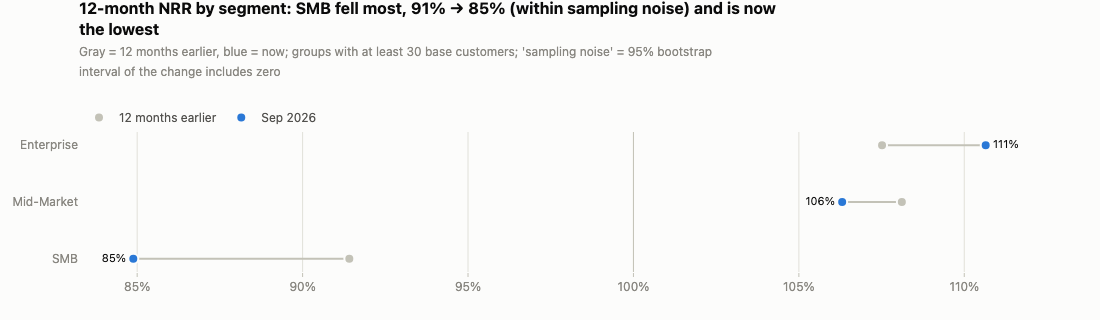

In [19]:
show(M.fig_segment_dumbbell('segment'))

In [20]:
seg = marts.load('metrics__segment_nrr')
seg[['dimension', 'dimension_value', 'base_customers', 'base_mrr', 'nrr', 'grr', 'nrr_year_ago', 'nrr_change']]

,dimension,dimension_value,base_customers,base_mrr,nrr,grr,nrr_year_ago,nrr_change
0,acquisition_channel,Outbound Sales,297,"338,704.5800",1.0336,0.8739,1.0202,0.0134
1,acquisition_channel,Organic,779,"256,959.5000",0.9914,0.8162,1.0838,-0.0924
2,acquisition_channel,Partner,315,"256,532.9000",1.2103,0.8899,1.1629,0.0474
3,acquisition_channel,Paid Search,615,"176,731.0000",0.9000,0.7775,0.9601,-0.0601
4,acquisition_channel,Events,205,"106,363.8800",1.0007,0.8801,0.9002,0.1005
5,acquisition_channel,Paid Social,166,"39,091.0000",0.8871,0.7293,0.9507,-0.0636
6,billing_at_start,annual,1075,"831,029.1600",1.0849,0.8807,1.0909,-0.0060
7,billing_at_start,monthly,1302,"343,353.7000",0.9143,0.7620,0.9458,-0.0315
8,industry,Technology,617,"286,427.8600",0.9555,0.8180,1.0948,-0.1393
9,industry,Financial Services,260,"160,074.5000",1.2252,0.8930,1.1545,0.0706


### 5. Cohorts

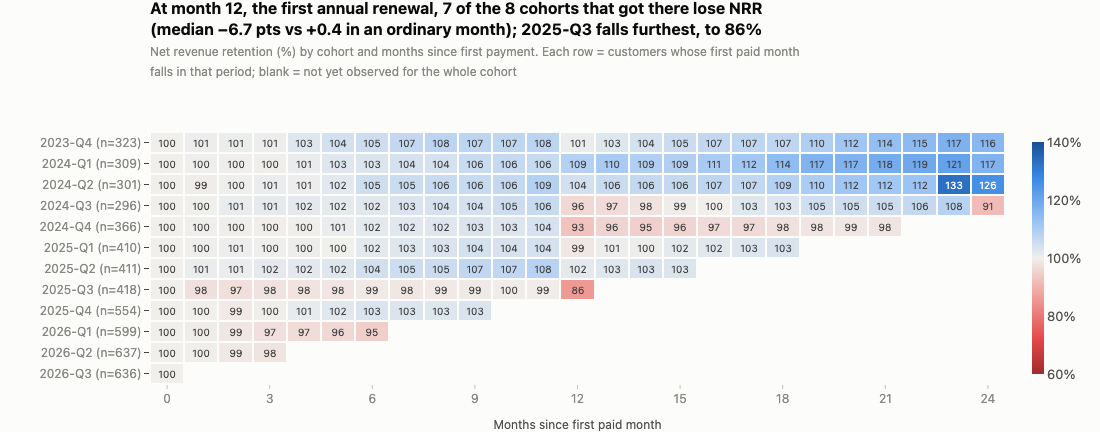

In [21]:
show(M.fig_cohort_heatmap('nrr', 'quarter'))

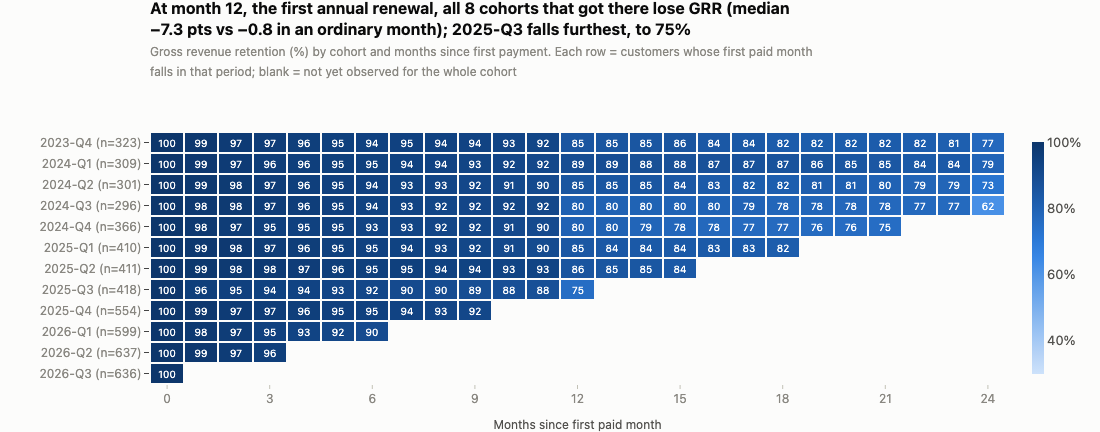

In [22]:
show(M.fig_cohort_heatmap('grr', 'quarter'))

In [23]:
m = M.cohort_matrix('nrr', 'quarter')
sizes = m.pop('customers')
ren = k['cohort_month12']
# renewal drops at month 12 and 24, with the calendar quarter in which each renewal fell
drops = []
for age in (12, 24):
    st_ = M.renewal_steps(m.assign(customers=sizes), age)
    for c, r in st_.iterrows():
        when = (pd.Period(c.replace('-', ''), freq='Q') + age // 3).strftime('%Y-Q%q')
        drops.append((r['step'], c, age, when))
drops.sort()
(s1, c1, a1, w1), (s2, c2, a2, w2) = drops[:2]
both_now = w1 == w2 == '2026-Q3'
m24 = m[24].dropna()
f_ = marts.load('fct_customer_mrr_monthly')
one_cohort = M.quarter_of(f_.loc[f_['customer_id'] == k['one_off_customer_id'], 'cohort_month_end']).iloc[0]
m6 = m[6].dropna()
low6, rest6 = m6[m6 < 1.0], m6[m6 >= 1.0]
low_txt = ' and '.join(f"{c} ({pct(v)})" for c, v in low6.items())
md(f"""**Reading.**
- **Month 12 is the first annual renewal.** {ren['cohorts_dipping']} of the {ren['cohorts']} cohorts that reached month 12 lose NRR there (median {pts(ren['median_step'])}
  vs {pts(ren['median_typical_step'])} in an ordinary month){'; ' + ', '.join(ren['exceptions']) + (' is the exception' if len(ren['exceptions']) == 1 else ' are the exceptions') if ren['exceptions'] else ''}.
  The drop sits with customers who started on annual billing (median {pts(k['cohort_month12_annual_median_step'])} at month 12; monthly-billed {pts(k['cohort_month12_monthly_median_step'])}),
  so it is contract timing, not a sudden change in the cohorts.
- **The two largest renewal drops** are {c1} at month {a1} ({pts(s1)}, renewal in {qname(w1)}) and {c2} at month {a2} ({pts(s2)}, renewal in {qname(w2)}){
  ' — both renewals fell in Q3 2026, the quarter in which Technology accounts cut seats' if both_now else ''}.
- **Two years in:** {', '.join(f"{c} {pct(v, 0)}" for c, v in m24.items())} at month 24 ({one_cohort} includes the one-off rollout). The 2023-Q4 cohort
  (design partners and early adopters) is {'not clearly ahead of' if abs(m24.get('2023-Q4', 0) - m24.get('2024-Q1', 0)) < 0.03 else 'different from'} 2024-Q1 at this age.
- **At month 6,** {low_txt or 'no cohort'} {'is' if len(low6) == 1 else 'are'} below 100%; every other cohort was at {pct(rest6.min())}–{pct(rest6.max())} — too few weak cohorts to call a trend.
  Cohort rows mix channels and seasons, so whether Paid Social signups retain worse is a channel comparison (see `05_recommendations`, P6), not something this table shows. Cohort size is in brackets.""")

**Reading.**
- **Month 12 is the first annual renewal.** 7 of the 8 cohorts that reached month 12 lose NRR there (median −6.7 pts
  vs +0.4 pts in an ordinary month); 2024-Q1 is the exception.
  The drop sits with customers who started on annual billing (median −10.3 pts at month 12; monthly-billed +0.3 pts),
  so it is contract timing, not a sudden change in the cohorts.
- **The two largest renewal drops** are 2024-Q3 at month 24 (−16.8 pts, renewal in Q3 2026) and 2025-Q3 at month 12 (−13.8 pts, renewal in Q3 2026) — both renewals fell in Q3 2026, the quarter in which Technology accounts cut seats.
- **Two years in:** 2023-Q4 116%, 2024-Q1 117%, 2024-Q2 126%, 2024-Q3 91% at month 24 (2024-Q2 includes the one-off rollout). The 2023-Q4 cohort
  (design partners and early adopters) is not clearly ahead of 2024-Q1 at this age.
- **At month 6,** 2025-Q3 (99.0%) and 2026-Q1 (94.6%) are below 100%; every other cohort was at 101.8%–105.1% — too few weak cohorts to call a trend.
  Cohort rows mix channels and seasons, so whether Paid Social signups retain worse is a channel comparison (see `05_recommendations`, P6), not something this table shows. Cohort size is in brackets.

### 6. Top movers in Q3 2026 (for the monthly review)

In [24]:
tm = M.top_movers('2026-Q3', n=8)
tm

,mover_type,customer_id,company_name,segment,industry,csm_owner,mrr_start,mrr_end,amount
0,expansion,CUS-002488,Redframe Wealth,Mid-Market,Financial Services,CSM-08,"2,940.0000","5,490.0000","2,550.0000"
1,expansion,CUS-002117,Primespark Insurance,Mid-Market,Financial Services,CSM-09,"8,008.0000","9,240.0000","1,232.0000"
2,expansion,CUS-002368,Coppergate Studios,SMB,Media & Marketing,NaN,720.0000,"1,575.0000","1,100.0000"
3,expansion,CUS-000162,Falconrock Care,Enterprise,Healthcare,CSM-02,"5,880.0000","6,972.0000","1,092.0000"
4,expansion,CUS-000755,Truelight Components,Mid-Market,Manufacturing,CSM-08,"5,865.0000","6,800.0000",935.0000
5,expansion,CUS-002496,Redport Fabrication,Mid-Market,Manufacturing,CSM-09,552.0000,"1,428.0000",876.0000
6,expansion,CUS-000073,Nextwood Manufacturing,Mid-Market,Manufacturing,CSM-07,"5,590.0000","6,450.0000",860.0000
7,expansion,CUS-003099,Peakstack Medical,Enterprise,Healthcare,CSM-01,"5,031.0000","5,891.0000",860.0000
8,contraction,CUS-001032,Peakcrest Health,Enterprise,Healthcare,CSM-04,"5,561.0000","3,320.0000","2,241.0000"
9,contraction,CUS-001209,Meridianridge Legal,Enterprise,Professional Services,CSM-04,"4,672.0000","3,029.5000","1,642.5000"


In [25]:
ci = M.nrr_change_interval(M.AS_OF, 'industry')
base = M.ttm_retention(M.AS_OF, 'industry').set_index('group')['base_customers']
half = (ci['change_hi'] - ci['change_lo']) / 2
md(f"""## Limitations
- **Synthetic data**: effect sizes come from generator rules (`docs/data_model.md §6`); the method, not the magnitudes, is what transfers.
- **Month-end snapshots** miss customers who start and cancel inside a month and net several changes within a month (counted in the data-quality checks).
- **Bridge attribution** puts each expanding account-month in one bucket by its dominant component; months mixing seat and plan changes are rare but the split there is a choice, not a measurement.
- **Seasonality** rests on two prior years; a third year would be needed to estimate it.
- **Correlation, not causation**: the fall in plan-upgrade expansion came mostly in {qname(plan_q)}{pkg_clause}, and overlaps a Paid Social mix shift — `02_plan_transitions`
  separates the packaging change, the mix shift and the earlier drift as far as the data allows; a holdout test is the only clean answer. The Technology slowdown coincides with the
  hiring freezes CSMs report; the data shows the timing, not the cause.
- **Segment NRR is noisy**: industries of {int(base.min()):,}–{int(base.max()):,} base customers carry 95% intervals of ±{pts(half.min(), 0).lstrip('+')} to ±{pts(half.max(), 0).lstrip('+')} on a year-over-year change (customer bootstrap); {'only ' if k['industry_nrr_falls_clear_of_noise'] == ['Technology'] else ''}Technology's fall
  ({pct(k['tech_nrr_2025_09'], 0)} → {pct(k['tech_nrr_2026_09'], 0)}, 95% interval {pts(k['tech_nrr_change_lo'], 0)} to {pts(k['tech_nrr_change_hi'], 0)}) is clear of that noise{' among industries' if k['industry_nrr_falls_clear_of_noise'] == ['Technology'] else ''}.""")

## Limitations
- **Synthetic data**: effect sizes come from generator rules (`docs/data_model.md §6`); the method, not the magnitudes, is what transfers.
- **Month-end snapshots** miss customers who start and cancel inside a month and net several changes within a month (counted in the data-quality checks).
- **Bridge attribution** puts each expanding account-month in one bucket by its dominant component; months mixing seat and plan changes are rare but the split there is a choice, not a measurement.
- **Seasonality** rests on two prior years; a third year would be needed to estimate it.
- **Correlation, not causation**: the fall in plan-upgrade expansion came mostly in Q1 2026, before the April packaging change, and overlaps a Paid Social mix shift — `02_plan_transitions`
  separates the packaging change, the mix shift and the earlier drift as far as the data allows; a holdout test is the only clean answer. The Technology slowdown coincides with the
  hiring freezes CSMs report; the data shows the timing, not the cause.
- **Segment NRR is noisy**: industries of 139–617 base customers carry 95% intervals of ±12 pts to ±30 pts on a year-over-year change (customer bootstrap); only Technology's fall
  (109% → 96%, 95% interval −26 pts to −2 pts) is clear of that noise among industries.

In [26]:
trigger_met = (k['expansion_rate_q3_2025'] - k['expansion_rate_q3_2026']) >= 0.01
md(f"""## Recommendations (detail in `05_recommendations`)
1. Board pack: report 12-month NRR with the definition footnote, show NRR excluding the one-off next to it, and add the Q3 run-rate as the leading indicator.
2. {'Treat the slowdown as structural (VP trigger met)' if trigger_met else 'Do not re-forecast yet (VP trigger not met)'}: re-forecast Q4 expansion with the Q3 like-for-like rate, and assign owners — CS for Technology accounts, Product for the Basic upgrade path.
3. Leave non-Tech seat expansion as it is for now: it grew year over year ({money(k['bridge_yoy']['Non-Tech seat expansion'])} against its Q3 2025 rate).

**What data I would want next:** pipeline / opportunity data for sales-assisted expansion, CRM notes on Technology accounts' headcount plans, and a randomised holdout for any packaging change.""")

## Recommendations (detail in `05_recommendations`)
1. Board pack: report 12-month NRR with the definition footnote, show NRR excluding the one-off next to it, and add the Q3 run-rate as the leading indicator.
2. Treat the slowdown as structural (VP trigger met): re-forecast Q4 expansion with the Q3 like-for-like rate, and assign owners — CS for Technology accounts, Product for the Basic upgrade path.
3. Leave non-Tech seat expansion as it is for now: it grew year over year ($9.4K against its Q3 2025 rate).

**What data I would want next:** pipeline / opportunity data for sales-assisted expansion, CRM notes on Technology accounts' headcount plans, and a randomised holdout for any packaging change.